# Gapminder: life expectancy and fertility, 1960–2015

My first project in the SPICED bootcamp: combine three Gapminder tables (fertility rate, life expectancy, population), reshape them into one long table and show how countries moved between 1960 and 2015, ending in an animated scatter plot.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation, PillowWriter

sns.set_theme(style='whitegrid')

## 1. Load and reshape

Each file has one row per country and one column per year. `melt` turns them into long format (country, year, value) so the three tables can be merged.

In [2]:
def load(path, value_name):
    reader = pd.read_excel if path.endswith('.xlsx') else pd.read_csv
    wide = reader(path, index_col=0)
    wide = wide.copy()
    wide.index.name = 'country'
    wide.columns = wide.columns.astype(int)
    return wide.reset_index().melt(id_vars='country', var_name='year', value_name=value_name)

fert = load('data/gapminder_total_fertility.csv', 'fertility_rate')
life = load('data/gapminder_lifeexpectancy.xlsx', 'life_expectancy')
pop = load('data/gapminder_population.xlsx', 'population')

df = fert.merge(life, on=['country', 'year']).merge(pop, on=['country', 'year']).dropna()
df = df[df['year'].between(1960, 2015)].reset_index(drop=True)
print(f"{df['country'].nunique()} countries, years {df['year'].min()}–{df['year'].max()}, {len(df):,} rows")
df.head()

201 countries, years 1960–2015, 11,250 rows


,country,year,fertility_rate,life_expectancy,population
0,Afghanistan,1960,7.67,31.94,8994793.0
1,Albania,1960,6.19,62.87,1636054.0
2,Algeria,1960,7.65,47.50,11124892.0
3,Angola,1960,7.32,35.98,5270844.0
4,Antigua and Barbuda,1960,4.43,62.97,54681.0


## 2. Three countries over time

Germany, China and Nigeria took very different paths.

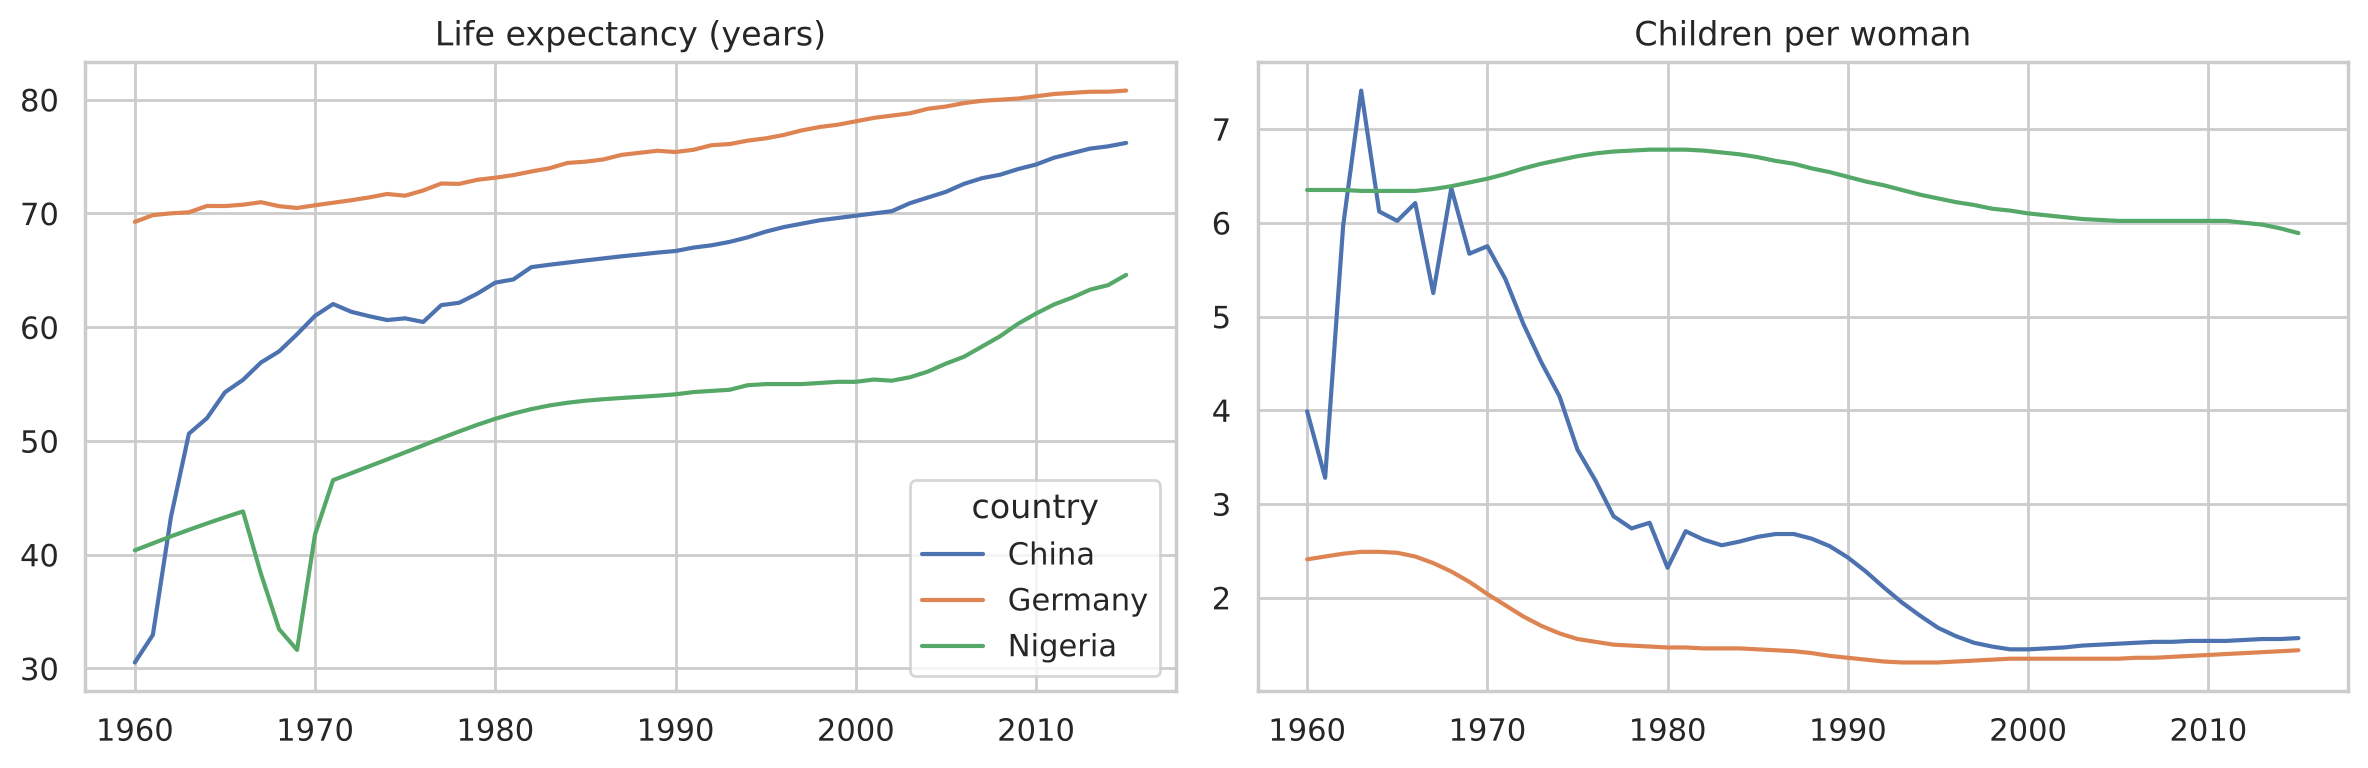

In [3]:
three = df[df['country'].isin(['Germany', 'China', 'Nigeria'])]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=three, x='year', y='life_expectancy', hue='country', ax=axes[0])
sns.lineplot(data=three, x='year', y='fertility_rate', hue='country', ax=axes[1], legend=False)
axes[0].set(title='Life expectancy (years)', xlabel='', ylabel='')
axes[1].set(title='Children per woman', xlabel='', ylabel='')
plt.tight_layout()

## 3. How are the two measures related?

Across all countries and years, a higher fertility rate goes with a lower life expectancy.

In [4]:
df[['life_expectancy', 'fertility_rate', 'population']].corr().round(2)

,life_expectancy,fertility_rate,population
life_expectancy,1.00,-0.81,0.02
fertility_rate,-0.81,1.00,-0.09
population,0.02,-0.09,1.00


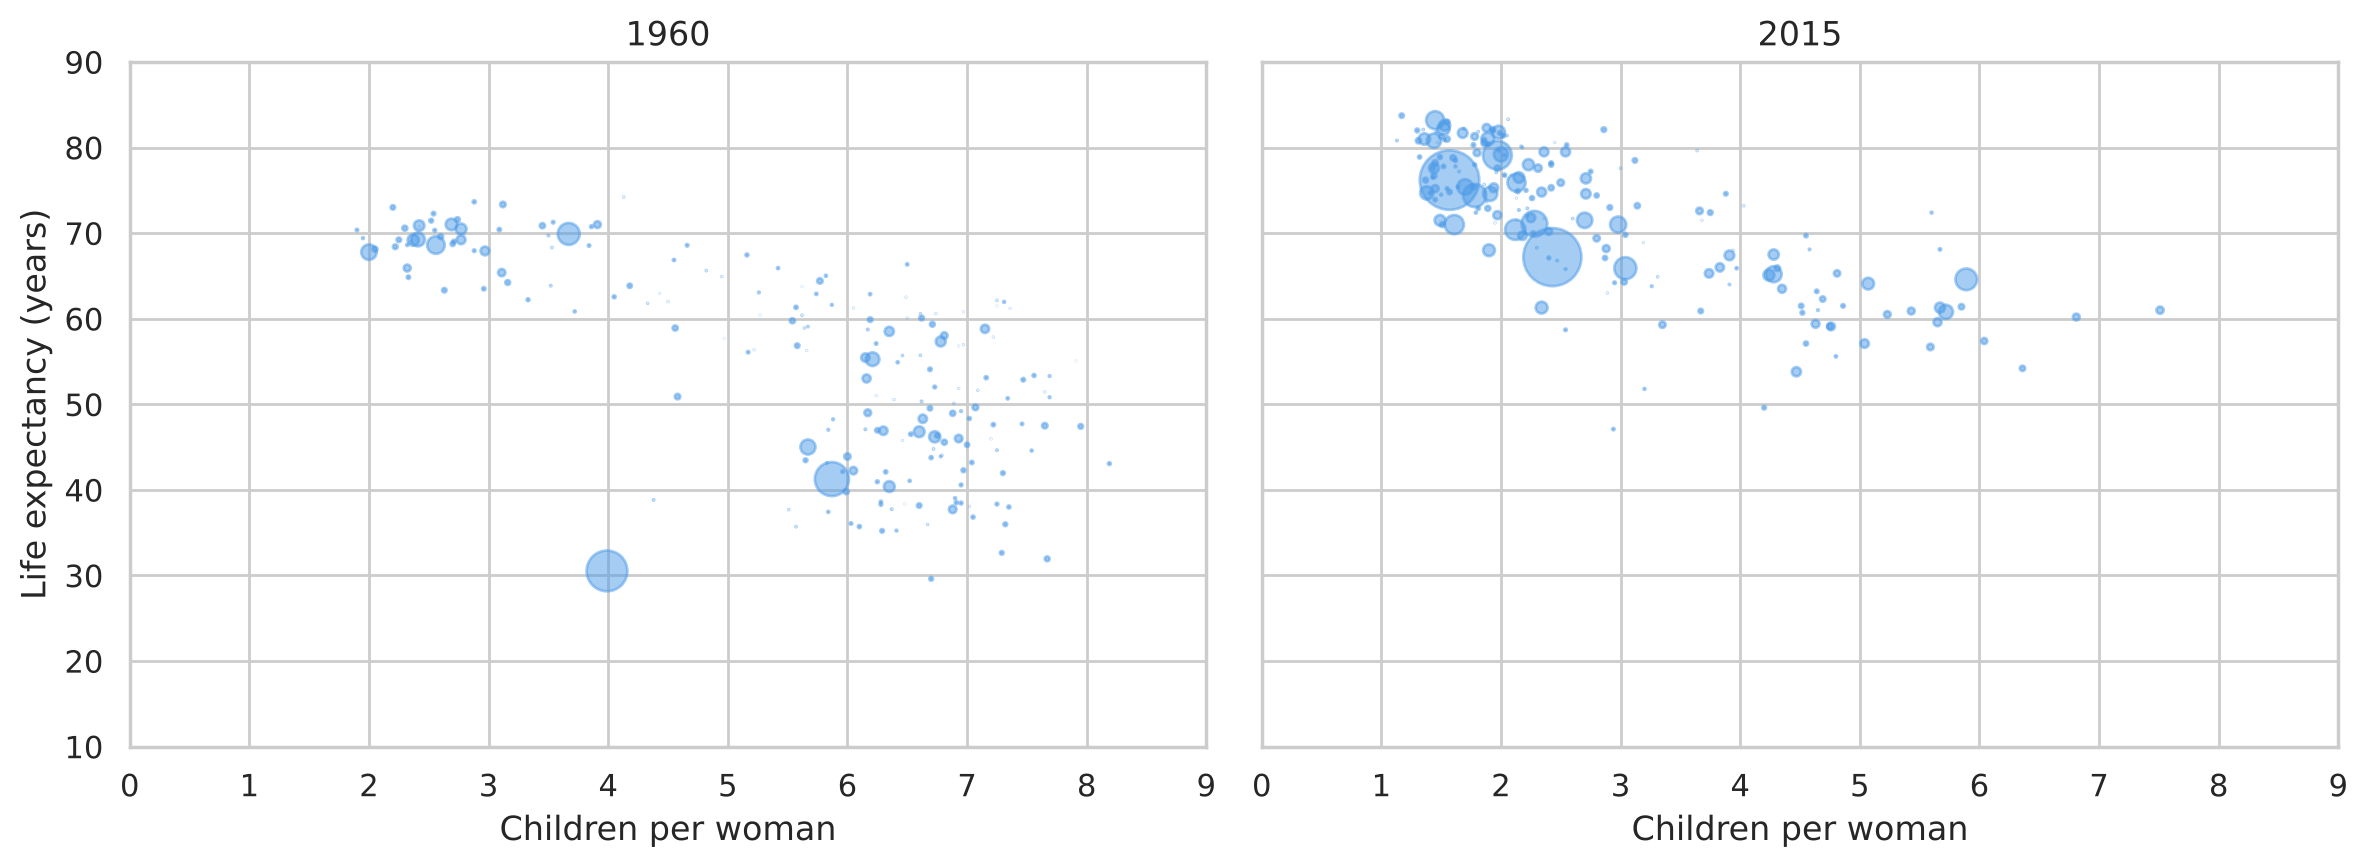

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
for ax, year in zip(axes, [1960, 2015]):
    d = df[df['year'] == year]
    ax.scatter(d['fertility_rate'], d['life_expectancy'], s=d['population'] / 3e6, alpha=0.5, color='#4C9BE8')
    ax.set(title=str(year), xlabel='Children per woman', xlim=(0, 9), ylim=(10, 90))
axes[0].set_ylabel('Life expectancy (years)')
plt.tight_layout()

## 4. Animation, 1960–2015

Bubble size shows population. Germany, China and Nigeria are labelled. The animation is saved as `gapminder.gif`.

In [6]:
HIGHLIGHT = {'Germany': '#E8704C', 'China': '#C0392B', 'Nigeria': '#27AE60'}
fig, ax = plt.subplots(figsize=(7, 5.5))

def draw(year):
    ax.clear()
    d = df[df['year'] == year]
    colors = [HIGHLIGHT.get(c, '#9DB4CC') for c in d['country']]
    ax.scatter(d['fertility_rate'], d['life_expectancy'], s=d['population'] / 4e6 + 5, c=colors, alpha=0.7, edgecolor='white')
    for name in HIGHLIGHT:
        row = d[d['country'] == name]
        if len(row):
            ax.annotate(name, (row['fertility_rate'].iloc[0], row['life_expectancy'].iloc[0]), xytext=(6, 6),
                        textcoords='offset points', fontsize=10, color=HIGHLIGHT[name], weight='bold')
    ax.text(0.97, 0.05, str(year), transform=ax.transAxes, ha='right', fontsize=32, color='#BBBBBB')
    ax.set(xlim=(0, 9), ylim=(20, 90), xlabel='Children per woman', ylabel='Life expectancy (years)',
           title='Life expectancy vs fertility rate')

years = range(1960, 2016)
anim = FuncAnimation(fig, draw, frames=years)
anim.save('gapminder.gif', writer=PillowWriter(fps=6), dpi=70)
plt.close(fig)
print('saved gapminder.gif')

saved gapminder.gif


![Gapminder animation](gapminder.gif)

## What the data shows

In 1960 most countries sat at the top left or bottom right: either few children and long lives, or many children and short lives. By 2015 most of the world had moved towards fewer children and longer lives. China moved early and fast; Nigeria's fertility rate stayed high for much longer.